# TA-03: Sistem Prediksi Pembatalan Reservasi Hotel Menggunakan Algoritma Logistic Regression
Mata kuliah Pembelajaran Mesin, Modul 03

**Studi kasus:** hotel ingin mengetahui reservasi mana yang berisiko dibatalkan, sehingga manajemen dapat mengatur overbooking, deposit, dan penawaran kamar dengan lebih baik.

**Dataset:** Hotel Booking Demand (Antonio, Almeida & Nunes, 2019), 119.390 reservasi dari City Hotel dan Resort Hotel di Portugal. Target: `is_canceled` (1 = batal, 0 = tidak batal).

In [1]:
import warnings; warnings.filterwarnings('ignore')
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, precision_score, recall_score, f1_score, accuracy_score)
from imblearn.over_sampling import SMOTE

os.makedirs('figures', exist_ok=True); os.makedirs('model', exist_ok=True)
sns.set_theme(style='whitegrid'); RS = 42

## 1. Pemuatan Data

In [2]:
df = pd.read_csv('hotels.csv')   # hotel_bookings.csv dari Kaggle (isi sama)
print('Ukuran data:', df.shape)
df.head()

Ukuran data: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
df.info()
print('\nNilai hilang per kolom:'); print(df.isna().sum()[lambda s: s > 0])

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

## 2. Eksplorasi Data (EDA)

### 2.1 Distribusi target dan ketidakseimbangan kelas

is_canceled
0    75166
1    44224
Name: count, dtype: int64
is_canceled
0    62.96 %
1    37.04 %
Name: count, dtype: str


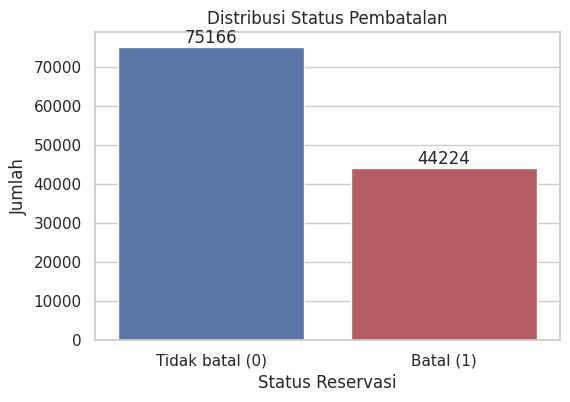

In [4]:
dist = df['is_canceled'].value_counts()
print(dist); print((dist / len(df) * 100).round(2).astype(str) + ' %')
plt.figure(figsize=(6,4))
ax = sns.countplot(x='is_canceled', data=df, palette=['#4C72B0', '#C44E52'])
ax.set_xticklabels(['Tidak batal (0)', 'Batal (1)'])
for p in ax.patches: ax.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
plt.title('Distribusi Status Pembatalan'); plt.xlabel('Status Reservasi'); plt.ylabel('Jumlah')
plt.savefig('figures/01_distribusi_target.png', dpi=150, bbox_inches='tight'); plt.show()

Kelas batal berjumlah sekitar 37%, sehingga ketidakseimbangannya ringan sampai sedang. SMOTE tetap dicoba pada data latih dan dibandingkan dengan model tanpa SMOTE.

### 2.2 Hubungan fitur dengan target

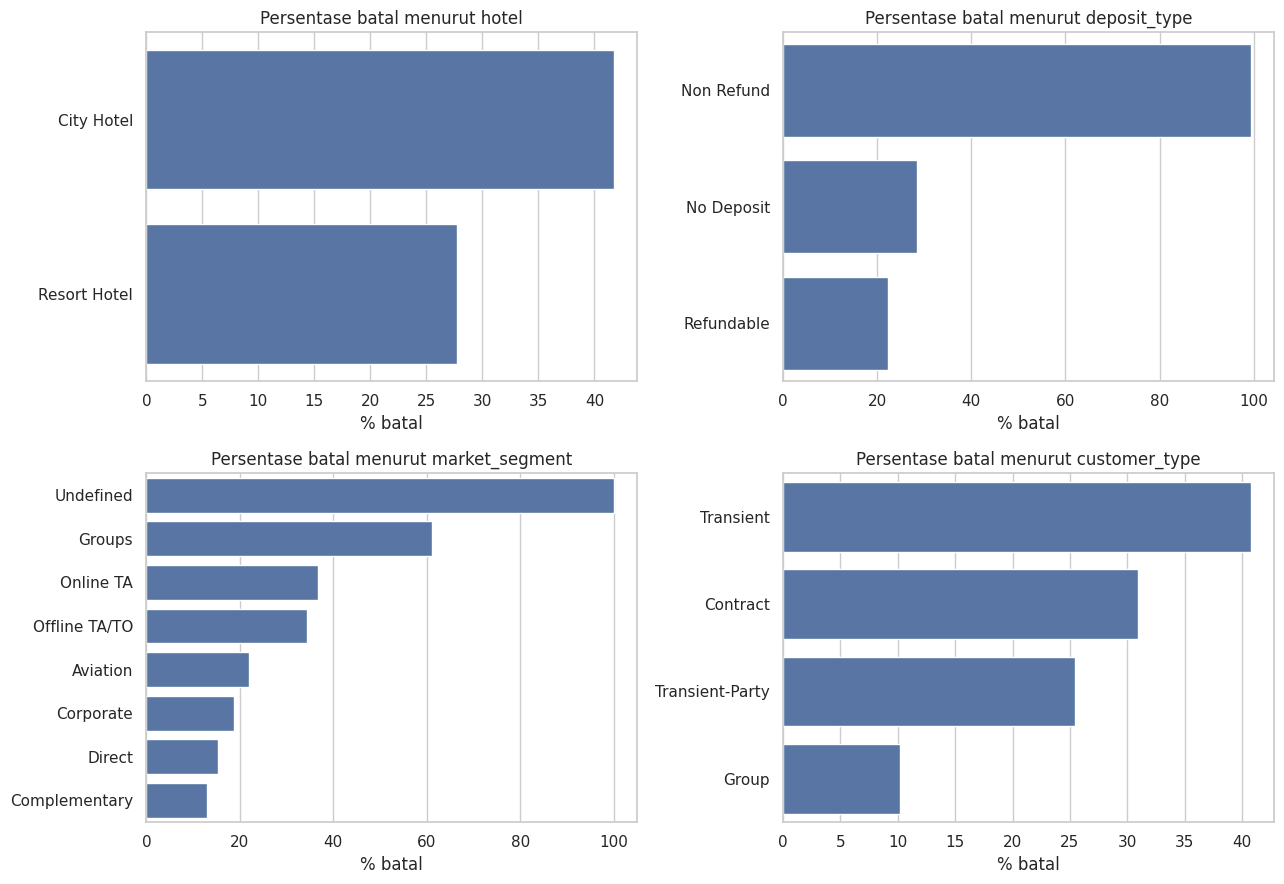

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.ravel(), ['hotel', 'deposit_type', 'market_segment', 'customer_type']):
    rate = df.groupby(col)['is_canceled'].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.values, y=rate.index, ax=ax, color='#4C72B0')
    ax.set_title(f'Persentase batal menurut {col}'); ax.set_xlabel('% batal'); ax.set_ylabel('')
plt.tight_layout(); plt.savefig('figures/02_batal_per_kategori.png', dpi=150); plt.show()

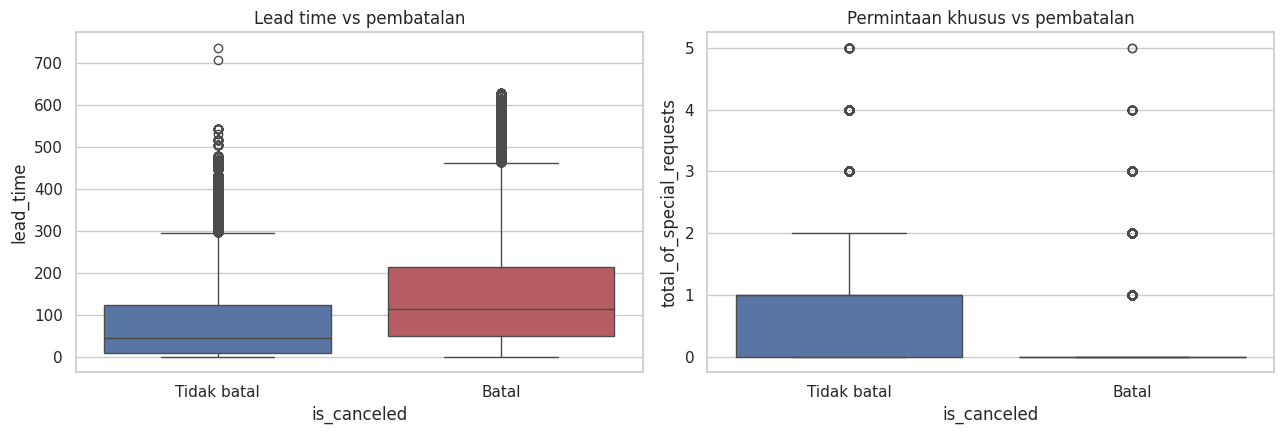

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(x='is_canceled', y='lead_time', data=df, ax=axes[0], palette=['#4C72B0', '#C44E52'])
axes[0].set_title('Lead time vs pembatalan'); axes[0].set_xticklabels(['Tidak batal', 'Batal'])
sns.boxplot(x='is_canceled', y='total_of_special_requests', data=df, ax=axes[1], palette=['#4C72B0', '#C44E52'])
axes[1].set_title('Permintaan khusus vs pembatalan'); axes[1].set_xticklabels(['Tidak batal', 'Batal'])
plt.tight_layout(); plt.savefig('figures/03_numerik_vs_target.png', dpi=150); plt.show()

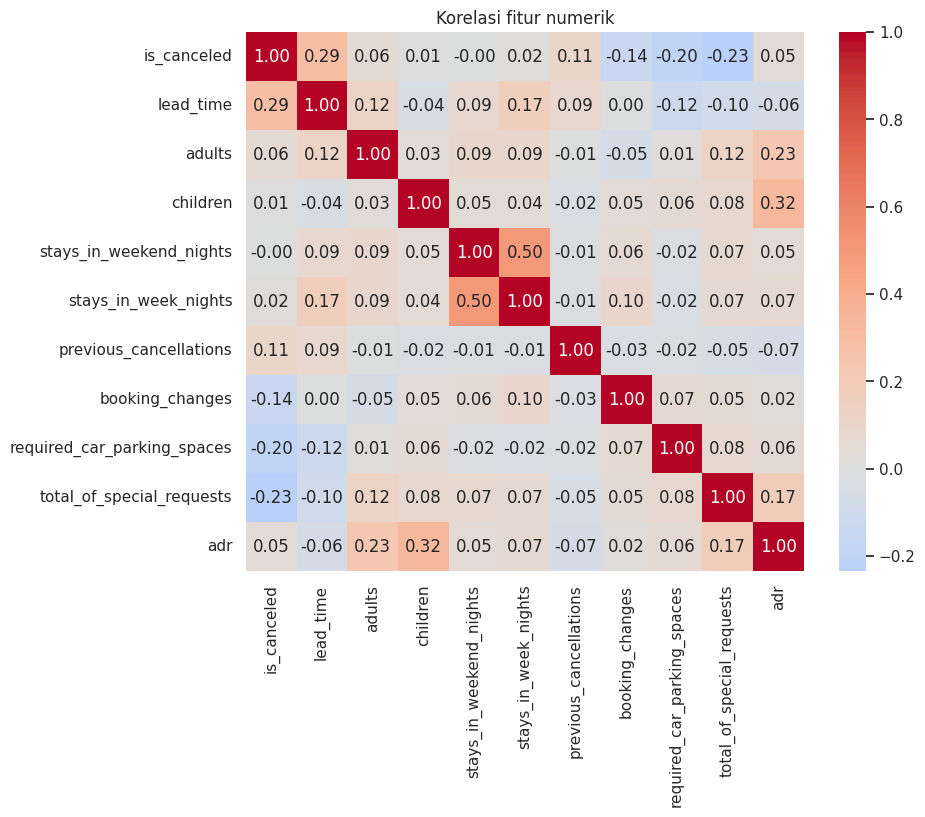

In [7]:
num_eda = ['is_canceled','lead_time','adults','children','stays_in_weekend_nights','stays_in_week_nights',
           'previous_cancellations','booking_changes','required_car_parking_spaces','total_of_special_requests','adr']
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_eda].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Korelasi fitur numerik'); plt.savefig('figures/04_korelasi.png', dpi=150, bbox_inches='tight'); plt.show()

## 3. Pra-pemrosesan Data
Langkah yang dilakukan:
1. **Menghapus kolom penyebab data leakage:** `reservation_status` dan `reservation_status_date` (status akhir reservasi, nyaris identik dengan target) serta `assigned_room_type` (baru diketahui setelah check-in).
2. Menghapus kolom ber-ID atau terlalu banyak nilai hilang: `agent`, `company`, `country`.
3. Mengisi nilai hilang `children` dengan 0.
4. Menghapus baris tidak wajar: `adr` negatif atau di atas 1000, dan reservasi tanpa tamu sama sekali.
5. Variabel kategorikal diubah dengan One-Hot Encoding, fitur numerik diskalakan dengan `StandardScaler`.

In [8]:
data = df.copy()
leak_cols = ['reservation_status', 'reservation_status_date', 'assigned_room_type']
id_cols = ['agent', 'company', 'country']
data = data.drop(columns=leak_cols + id_cols)
data['children'] = data['children'].fillna(0)

n0 = len(data)
data = data[(data['adr'] >= 0) & (data['adr'] <= 1000)]
data = data[(data['adults'] + data['children'] + data['babies']) > 0]
print(f'Baris dihapus: {n0 - len(data)} | sisa: {len(data)}')

num_cols = ['lead_time', 'adults', 'children', 'stays_in_weekend_nights', 'stays_in_week_nights',
            'previous_cancellations', 'booking_changes', 'required_car_parking_spaces',
            'total_of_special_requests', 'adr', 'is_repeated_guest']
cat_cols = ['hotel', 'market_segment', 'deposit_type', 'customer_type']
features = num_cols + cat_cols
X = data[features]; y = data['is_canceled']
X.head()

Baris dihapus: 182 | sisa: 119208


,lead_time,adults,children,stays_in_weekend_nights,stays_in_week_nights,previous_cancellations,booking_changes,required_car_parking_spaces,total_of_special_requests,adr,is_repeated_guest,hotel,market_segment,deposit_type,customer_type
0,342,2,0.0,0,0,0,3,0,0,0.0,0,Resort Hotel,Direct,No Deposit,Transient
1,737,2,0.0,0,0,0,4,0,0,0.0,0,Resort Hotel,Direct,No Deposit,Transient
2,7,1,0.0,0,1,0,0,0,0,75.0,0,Resort Hotel,Direct,No Deposit,Transient
3,13,1,0.0,0,1,0,0,0,0,75.0,0,Resort Hotel,Corporate,No Deposit,Transient
4,14,2,0.0,0,2,0,0,0,1,98.0,0,Resort Hotel,Online TA,No Deposit,Transient


## 4. Pembagian Data dan Scaling

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Proporsi batal (train):', round(y_train.mean(), 3), '| (test):', round(y_test.mean(), 3))

scaled_cols = [c for c in num_cols if c != 'is_repeated_guest']
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), scaled_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), cat_cols),
], remainder='passthrough')   # is_repeated_guest (biner) diteruskan apa adanya

Xtr = preprocessor.fit_transform(X_train)      # scaler hanya di-fit pada data latih
Xte = preprocessor.transform(X_test)
feature_names = list(preprocessor.get_feature_names_out())
print('Jumlah fitur setelah encoding:', Xtr.shape[1])

Train: (95366, 15) | Test: (23842, 15)
Proporsi batal (train): 0.371 | (test): 0.371
Jumlah fitur setelah encoding: 24


## 5. Pemodelan Regresi Logistik

### 5.1 Model dasar (tanpa SMOTE)

In [10]:
lr_base = LogisticRegression(solver='lbfgs', max_iter=1000, random_state=RS)
lr_base.fit(Xtr, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

### 5.2 Model dengan SMOTE pada data latih

In [11]:
sm = SMOTE(random_state=RS)
Xtr_sm, ytr_sm = sm.fit_resample(Xtr, y_train)
print('Sebelum SMOTE:', np.bincount(y_train), '| Sesudah SMOTE:', np.bincount(ytr_sm))
lr_smote = LogisticRegression(solver='lbfgs', max_iter=1000, random_state=RS)
lr_smote.fit(Xtr_sm, ytr_sm)

Sebelum SMOTE: [60008 35358] | Sesudah SMOTE: [60008 60008]


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

## 6. Evaluasi Model

In [12]:
def evaluate(name, model):
    pred = model.predict(Xte); proba = model.predict_proba(Xte)[:, 1]
    return {'Model': name, 'Accuracy': accuracy_score(y_test, pred),
            'Precision': precision_score(y_test, pred), 'Recall': recall_score(y_test, pred),
            'F1-Score': f1_score(y_test, pred), 'AUC': roc_auc_score(y_test, proba)}
cmp = pd.DataFrame([evaluate('LogReg tanpa SMOTE', lr_base), evaluate('LogReg + SMOTE', lr_smote)]).set_index('Model').round(4)
cmp

,Accuracy,Precision,Recall,F1-Score,AUC
Model,,,,,
LogReg tanpa SMOTE,0.8024,0.8303,0.5869,0.6877,0.8465
LogReg + SMOTE,0.7772,0.6949,0.7114,0.7031,0.8472


In [13]:
# Pemilihan model akhir: Recall kelas 'batal' diprioritaskan, AUC sebagai pembanding
final_name = cmp['Recall'].idxmax()
model = lr_smote if final_name == 'LogReg + SMOTE' else lr_base
print('Model akhir:', final_name)
pred = model.predict(Xte); proba = model.predict_proba(Xte)[:, 1]
print(classification_report(y_test, pred, target_names=['Tidak batal', 'Batal'], digits=4))

Model akhir: LogReg + SMOTE
              precision    recall  f1-score   support

 Tidak batal     0.8275    0.8160    0.8217     15002
       Batal     0.6949    0.7114    0.7031      8840

    accuracy                         0.7772     23842
   macro avg     0.7612    0.7637    0.7624     23842
weighted avg     0.7784    0.7772    0.7777     23842



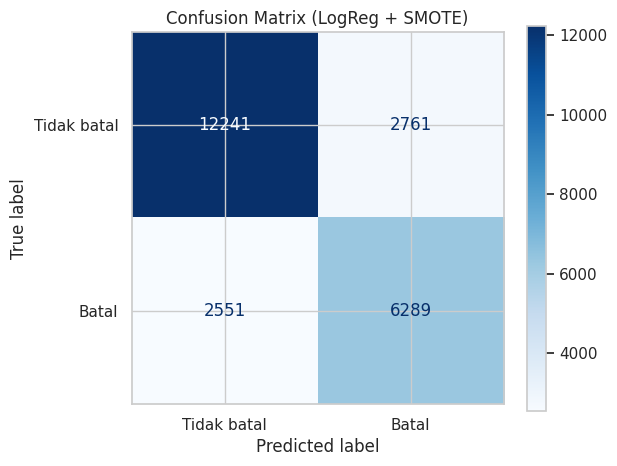

TN=12241 | FP=2761 | FN=2551 | TP=6289


In [14]:
cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=['Tidak batal', 'Batal']).plot(cmap='Blues', ax=ax, values_format='d')
plt.title(f'Confusion Matrix ({final_name})'); plt.savefig('figures/05_confusion_matrix.png', dpi=150, bbox_inches='tight'); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f'TN={tn} | FP={fp} | FN={fn} | TP={tp}')

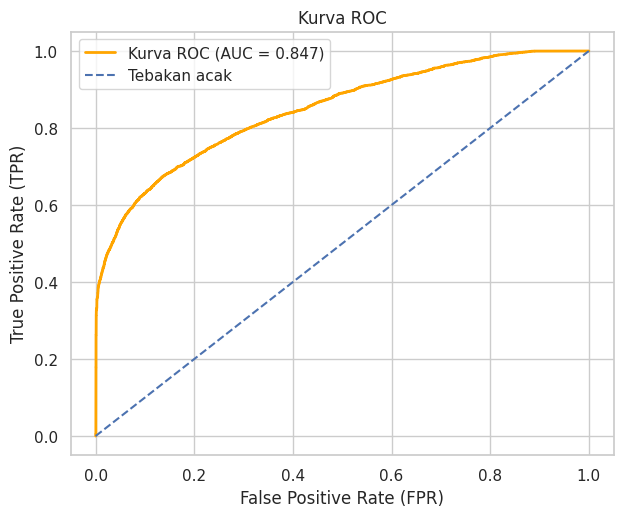

AUC = 0.8472


In [15]:
fpr, tpr, thr = roc_curve(y_test, proba); auc = roc_auc_score(y_test, proba)
plt.figure(figsize=(7, 5.5))
plt.plot(fpr, tpr, color='orange', lw=2, label=f'Kurva ROC (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'b--', label='Tebakan acak')
plt.xlabel('False Positive Rate (FPR)'); plt.ylabel('True Positive Rate (TPR)')
plt.title('Kurva ROC'); plt.legend(); plt.grid(True)
plt.savefig('figures/06_roc.png', dpi=150, bbox_inches='tight'); plt.show()
print(f'AUC = {auc:.4f}')

### Pengaruh threshold terhadap Precision dan Recall

In [16]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6]:
    p = (proba >= t).astype(int)
    rows.append({'Threshold': t, 'Precision': precision_score(y_test, p), 'Recall': recall_score(y_test, p),
                 'F1-Score': f1_score(y_test, p), 'FN': int(((p == 0) & (y_test == 1)).sum()), 'FP': int(((p == 1) & (y_test == 0)).sum())})
thr_df = pd.DataFrame(rows).round(4); thr_df

,Threshold,Precision,Recall,F1-Score,FN,FP
0,0.3,0.5157,0.8867,0.6521,1002,7361
1,0.4,0.5951,0.8060,0.6847,1715,4848
2,0.5,0.6949,0.7114,0.7031,2551,2761
3,0.6,0.8018,0.6207,0.6997,3353,1356


## 7. Interpretasi Koefisien (Odds Ratio)

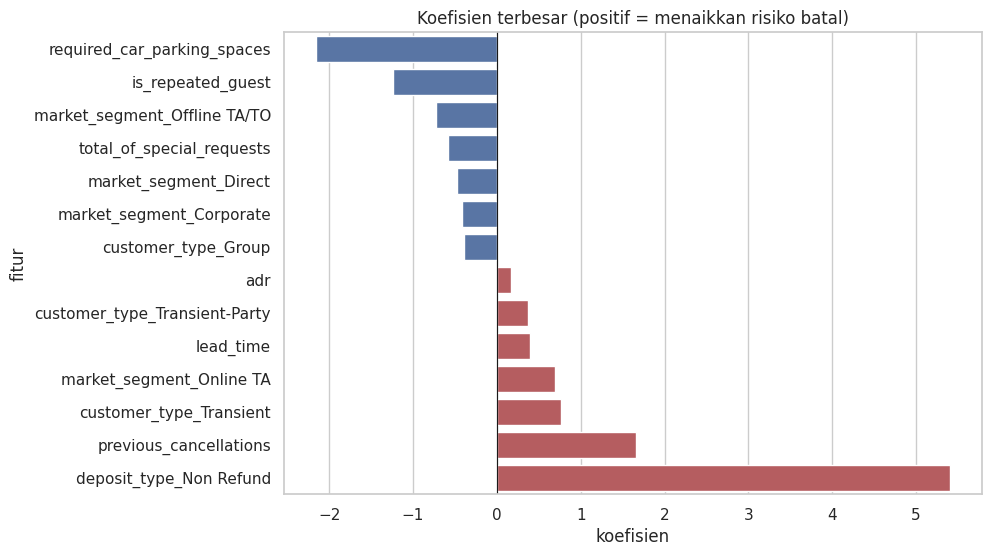

,fitur,koefisien,odds_ratio
18,deposit_type_Non Refund,5.405,222.579
5,previous_cancellations,1.657,5.241
21,customer_type_Transient,0.763,2.146
16,market_segment_Online TA,0.693,2.001
0,lead_time,0.401,1.493
22,customer_type_Transient-Party,0.368,1.445
9,adr,0.168,1.182
4,stays_in_week_nights,0.091,1.095
1,adults,0.068,1.070
3,stays_in_weekend_nights,0.051,1.052


In [17]:
coef = pd.DataFrame({'fitur': feature_names, 'koefisien': model.coef_[0]})
coef['fitur'] = coef['fitur'].str.replace('num__', '').str.replace('cat__', '').str.replace('remainder__', '')
coef['odds_ratio'] = np.exp(coef['koefisien'])
coef = coef.sort_values('koefisien')
top = pd.concat([coef.head(7), coef.tail(7)])
plt.figure(figsize=(9, 6))
sns.barplot(x='koefisien', y='fitur', data=top, palette=['#C44E52' if v > 0 else '#4C72B0' for v in top['koefisien']])
plt.title('Koefisien terbesar (positif = menaikkan risiko batal)'); plt.axvline(0, color='k', lw=.8)
plt.savefig('figures/07_koefisien.png', dpi=150, bbox_inches='tight'); plt.show()
coef.sort_values('koefisien', ascending=False).round(3).head(10)

## 8. Penyimpanan Model dan Scaler (Joblib)

In [18]:
joblib.dump(preprocessor, 'model/preprocessor.joblib')   # berisi StandardScaler + OneHotEncoder
joblib.dump(model, 'model/logreg_model.joblib')
meta = {'features': features, 'num_cols': num_cols, 'cat_cols': cat_cols, 'model': final_name,
        'metrics': cmp.loc[final_name].round(4).to_dict(),
        'categories': {c: sorted(X[c].unique().tolist()) for c in cat_cols}}
json.dump(meta, open('model/meta.json', 'w'), indent=2)
print(os.listdir('model'))

['preprocessor.joblib', 'logreg_model.joblib', 'meta.json']


## 9. Kesimpulan dan Wawasan Bisnis

In [19]:
from IPython.display import Markdown
m = cmp.loc[final_name]
Markdown(f'''
- Model akhir: **{final_name}** dengan Accuracy **{m['Accuracy']:.3f}**, Precision **{m['Precision']:.3f}**, Recall **{m['Recall']:.3f}**, F1-Score **{m['F1-Score']:.3f}**, dan AUC **{m['AUC']:.3f}**.
- Dari {tp+fn} reservasi yang benar-benar batal pada data uji, model menangkap {tp} (False Negative = {fn}). Sebanyak {fp} reservasi yang sebenarnya tidak batal salah ditandai batal (False Positive = {fp}).
- **False Negative lebih merugikan:** reservasi batal yang tidak terdeteksi membuat kamar kosong tanpa sempat dijual ulang. False Positive hanya berakibat hotel menghubungi tamu atau meminta konfirmasi tambahan. Karena itu **Recall** kelas batal menjadi metrik utama, dengan Precision dijaga agar tidak terlalu rendah.
- Tidak ada data leakage: `reservation_status` dan kolom terkait sudah dibuang, sehingga AUC tidak mendekati 1.00.
''')


- Model akhir: **LogReg + SMOTE** dengan Accuracy **0.777**, Precision **0.695**, Recall **0.711**, F1-Score **0.703**, dan AUC **0.847**.
- Dari 8840 reservasi yang benar-benar batal pada data uji, model menangkap 6289 (False Negative = 2551). Sebanyak 2761 reservasi yang sebenarnya tidak batal salah ditandai batal (False Positive = 2761).
- **False Negative lebih merugikan:** reservasi batal yang tidak terdeteksi membuat kamar kosong tanpa sempat dijual ulang. False Positive hanya berakibat hotel menghubungi tamu atau meminta konfirmasi tambahan. Karena itu **Recall** kelas batal menjadi metrik utama, dengan Precision dijaga agar tidak terlalu rendah.
- Tidak ada data leakage: `reservation_status` dan kolom terkait sudah dibuang, sehingga AUC tidak mendekati 1.00.
